# Unidades 17, 18 y 19: Funciones, Recursion y Lambda

**Funciones (def), Recursion y Expresiones lambda con funciones de orden superior (map, filter, reduce)**

## Unidad 17: Funciones

Una **funcion** es un bloque de codigo con nombre que realiza una tarea concreta y se puede reutilizar. Dividir un programa en funciones (programacion modular) lo hace mas legible, ordenado y facil de mantener.

### 17.1 Fundamentos: definir y llamar funciones

**Problema que resuelve:** evitar repetir el mismo codigo en varios lugares.

- `def nombre(parametros):` **define** la funcion (con dos puntos y el cuerpo indentado). Definir no ejecuta nada.
- `nombre(argumentos)` **llama** a la funcion y ejecuta su cuerpo.
- Una funcion recibe datos, los procesa y puede devolver un resultado con `return`.
- Error clasico: escribir `saludar` sin parentesis no la ejecuta.

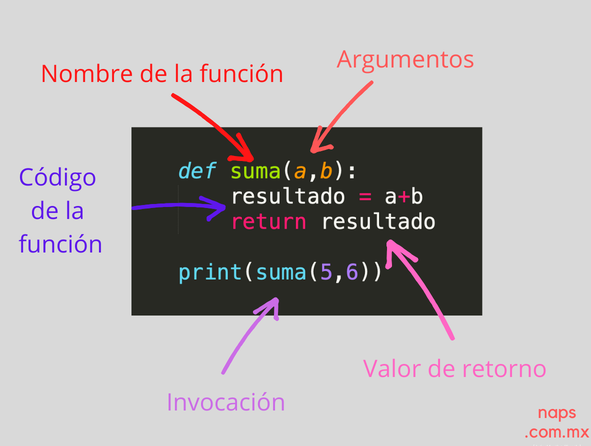

In [ ]:
# Ejemplo 1 (General): definir y llamar una funcion
def saludar_usuario():
    print("Hola, bienvenido al curso de Python")

print("Antes de llamar a la funcion")
saludar_usuario()
saludar_usuario()

print('+' * 20)

# Sin funciones: la logica se repite
precio_cuaderno = 2.00
print("Cuaderno:", round(precio_cuaderno * 1.07, 2)) # En Panama el impuesto es del 7%
precio_lapicero = 3.00
print("Lapicero:", round(precio_lapicero * 1.07, 2))


# Con funciones: la logica se escribe una sola vez
def calcular_precio_con_iva(precio):
    return round(precio * 1.12, 2)

print("Cuaderno:", calcular_precio_con_iva(2.00))
print("Lapicero:", calcular_precio_con_iva(3.00))

# Sin parentesis no se ejecuta, solo se muestra el objeto funcion
print(type(saludar_usuario))

Antes de llamar a la funcion
Hola, bienvenido al curso de Python
Hola, bienvenido al curso de Python
++++++++++++++++++++
Cuaderno: 2.14
Lapicero: 3.21
Cuaderno: 2.24
Lapicero: 3.36
<class 'function'>


### 17.2 Parametros y argumentos

**Problema que resuelve:** que una misma funcion trabaje con datos distintos en cada llamada.

| | Parametro | Argumento |
|---|---|---|
| Donde aparece | En el `def` | En la llamada |
| Que es | Un nombre (variable) | Un valor concreto |
| Ejemplo | `nombre`, `edad` | `"Ana"`, `20` |

- Los **argumentos posicionales** se asignan por orden: el primero al primer parametro, etc.
- Si faltan o sobran argumentos, Python lanza `TypeError`.

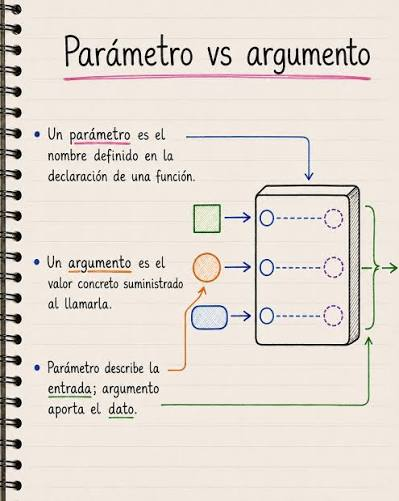

In [ ]:
def presentar(nombre, edad):          # nombre y edad son PARAMETROS
    print(f"{nombre} tiene {edad} años")


presentar("Ana", 20)                  # "Ana" y 20 son ARGUMENTOS
presentar("Luis", 35)
presentar(20, "Ana")                  # el orden importa: no falla, pero da/pierde sentido

try:
    presentar("Ana")                  # falta un argumento
except TypeError as error:
    print("Error:", error)

try:
    presentar("Ana", 20, "extra")     # sobra un argumento
except TypeError as error:
    print("Error:", error)

Ana tiene 20 años
Luis tiene 35 años
20 tiene Ana años
Error: presentar() missing 1 required positional argument: 'edad'
Error: presentar() takes 2 positional arguments but 3 were given


### 17.3 Tipos de parametros: predeterminados, palabra clave y *args **kwargs

**Problema que resuelve:** hacer funciones flexibles sin escribir una version por cada caso.

- **Parametro obligatorio:** debe recibir un valor en la llamada.
- **Parametro predeterminado:** `parametro=valor`; si no se envia, usa ese valor. Va **despues** de los obligatorios.
- **Argumento de palabra clave:** `nombre=valor` en la llamada; el orden deja de importar porque Python asigna por nombre.
- **`*args`:** reune los argumentos posicionales adicionales en una **tupla**. Con una lista como parametro hay que armar la lista; con `*args` se escriben los valores sueltos.
- **Orden recomendado:** obligatorios, `*args`, y despues los predeterminados (que quedan solo por palabra clave).

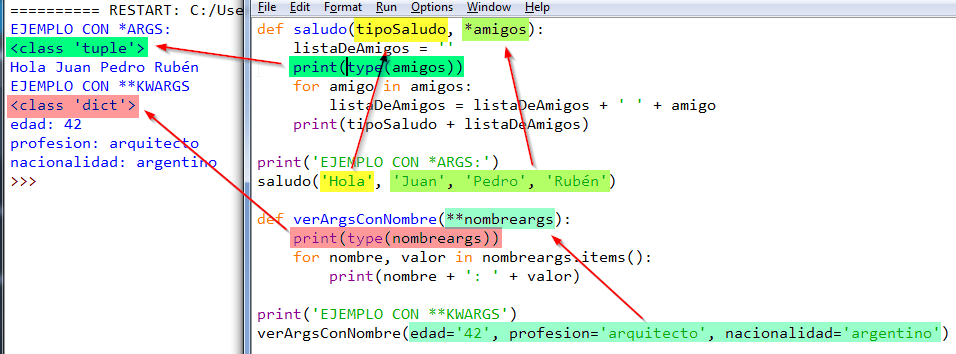

In [ ]:
def calcular_precio_final(precio, descuento=0.0, impuesto=0.07):
    precio_con_descuento = precio * (1 - descuento)
    return round(precio_con_descuento * (1 + impuesto), 2)

print(calcular_precio_final(100))                               # usa los valores por defecto
print(calcular_precio_final(100, 0.10))                         # descuento posicional
print(calcular_precio_final(100, impuesto=0.0, descuento=0.2))  # palabras clave en otro orden

# *args = Argumentos posicionales, o extras sin nombre

# **kwargs = Argumentos con nombre , que tienen de clave:valor


def sumar_todos(*numeros):
    print("numeros es una", type(numeros), numeros)
    return sum(numeros)

print(sumar_todos(1, 2))
print(sumar_todos())

lista_guardada = [4, 5, 6]
print(sumar_todos(*lista_guardada))        # el * desempaqueta la lista en argumentos sueltos




def registrar_compra(cliente, *articulos, moneda="USD"):
    return f"{cliente} compro: {', '.join(articulos)} ({moneda})"

print(registrar_compra("Ana", "pan", "leche", "queso"))
print(registrar_compra("Luis", "arroz", moneda="PAB"))

107.0
96.3
80.0
numeros es una <class 'tuple'> (1, 2)
3
numeros es una <class 'tuple'> ()
0
numeros es una <class 'tuple'> (4, 5, 6)
15
Ana compro: pan, leche, queso (USD)
Luis compro: arroz (PAB)


### 17.4 La sentencia return

**Problema que resuelve:** entregar un resultado para guardarlo o reutilizarlo en otros calculos.

- `return` termina la funcion y devuelve un valor.
- `print()` solo muestra en pantalla; `return` entrega el valor al codigo que llamo.
- Una funcion sin `return` devuelve `None`.
- `return a, b` **empaqueta** varios valores en una **tupla**; al llamar se pueden **desempaquetar** en variables.
- El modulo `math` (biblioteca estandar, se importa con `import math`) aporta `math.pi`.

In [ ]:
# print vs return, y varios valores
import math

def mostrar_doble(numero):
    print(numero * 2)

def calcular_doble(numero):
    return numero * 2

resultado_mostrar = mostrar_doble(5)
print("mostrar_doble devolvio:", resultado_mostrar)
resultado_calcular = calcular_doble(5)
print("calcular_doble devolvio:", resultado_calcular, "| reutilizado x3:", calcular_doble(5) * 3)

#-------------------------------------------------

def calcular_area_y_circunferencia(radio):
    area = math.pi * radio ** 2
    circunferencia = 2 * math.pi * radio
    return area, circunferencia

resultado_circulo = calcular_area_y_circunferencia(5)
print(resultado_circulo, type(resultado_circulo))

area_circulo, circunferencia_circulo = calcular_area_y_circunferencia(5)
print(f"Area: {area_circulo:.2f} | Circunferencia: {circunferencia_circulo:.2f}")

10
mostrar_doble devolvio: None
calcular_doble devolvio: 10 | reutilizado x3: 30
(78.53981633974483, 31.41592653589793) <class 'tuple'>
Area: 78.54 | Circunferencia: 31.42


### 17.5 Procesamiento de cadenas de texto

**Problema que resuelve:** limpiar, comparar y medir texto sin programar cada operacion.

Metodos de cadena (se llaman con punto sobre el texto y **devuelven una cadena nueva**; las cadenas son inmutables):

| Metodo | Devuelve |
|---|---|
| `.count(sub)` | Cuantas veces aparece `sub` (distingue mayusculas) |
| `.upper()` / `.lower()` | Texto en mayusculas / minusculas |
| `.swapcase()` | Invierte mayusculas y minusculas |
| `.istitle()` | `True` si cada palabra empieza con mayuscula |

Funciones incorporadas (el dato va **dentro** de los parentesis): `len()` cantidad de caracteres, `max()`/`min()` mayor y menor segun su codigo, `ord()` caracter a codigo Unicode y `chr()` codigo a caracter.

In [ ]:
# metodos y funciones sobre texto
frase = "Hola Mundo, hola GT-B"

print(frase.count("hola"), "| ignorando mayusculas:", frase.lower().count("hola"))
print(frase.count(" "), "espacios")
print(frase.upper())
print(frase.lower())
print(frase.swapcase())
print("Hola Mundo".istitle(), "Hola mundo".istitle())

# Unicode: acentos y eñies
print("canción".upper(), "ÑANDÚ".lower(), len("canción"))

# El metodo no modifica el original
palabra = "python"
palabra.upper()
print(palabra)
palabra = palabra.upper()
print(palabra)

1 | ignorando mayusculas: 2
3 espacios
HOLA MUNDO, HOLA GT-B
hola mundo, hola gt-b
hOLA mUNDO, HOLA gt-b
True False
CANCIÓN ñandú 7
python
PYTHON


### 17.6 Ambito de las variables

**Problema que resuelve:** saber donde existe una variable y evitar cambios accidentales.

- **Variable local:** se crea dentro de una funcion y solo existe mientras esta se ejecuta.
- **Variable global:** se crea fuera de las funciones; las funciones pueden **leerla**.
- Para **reasignar** una global dentro de una funcion hace falta `global nombre`; sin eso Python crea una local nueva.
- Conviene evitar las globales innecesarias: es mejor pasar datos por parametros y devolver resultados.
- **Constantes por convencion:** se escriben en MAYUSCULAS (`IVA`, `PI`). Python **no impide** modificarlas; es solo una señal para los programadores.

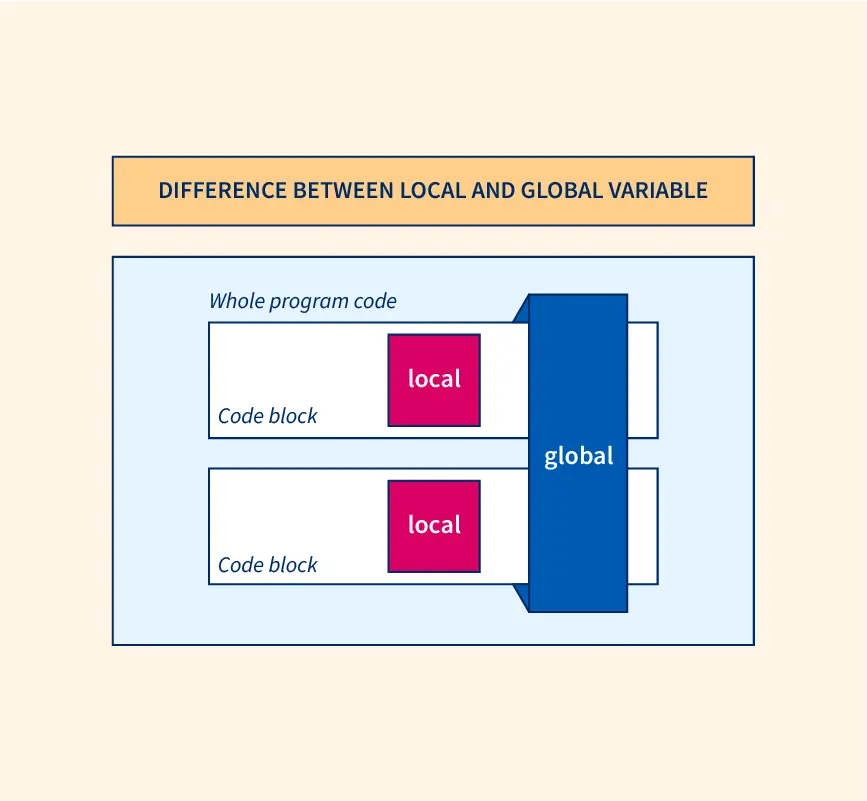

In [ ]:
# local, global y constantes

mensaje = "Global"

def mostar_mensaje():
  secreto = "local"
  print(mensaje) # global
  print(secreto) # local

mostar_mensaje()

print(mensaje)
# print(secreto)

Global
local
Global


In [ ]:
contador = 0 # global

print(contador)

def sumar_uno():
  global contador
  contador = contador + 1

sumar_uno()
sumar_uno()
sumar_uno()

print(contador)

0
3


In [ ]:
contador = 0

def sumar_uno():
  global contador
  contador = contador + 1
  print(contador)

sumar_uno()
print(contador)

1
1


### 17.7 Funciones frente a metodos

**Problema que resuelve:** entender la diferencia entre `len(texto)` y `texto.upper()`, y como se organizan datos y comportamiento juntos.

- **Funcion independiente:** no pertenece a ningun objeto; se llama como `len(texto)`.
- **Metodo:** funcion que pertenece a un **objeto** y trabaja con sus datos; se llama como `texto.upper()`.
- `class` define un molde; una **instancia** es un objeto creado con ese molde; los **atributos** son los datos del objeto.
- `__init__` se ejecuta al crear la instancia y le da sus valores iniciales.
- `self` es el primer parametro de los metodos de instancia: representa la instancia que llama. Python lo pasa solo: `obj.metodo()` equivale a `Clase.metodo(obj)`.

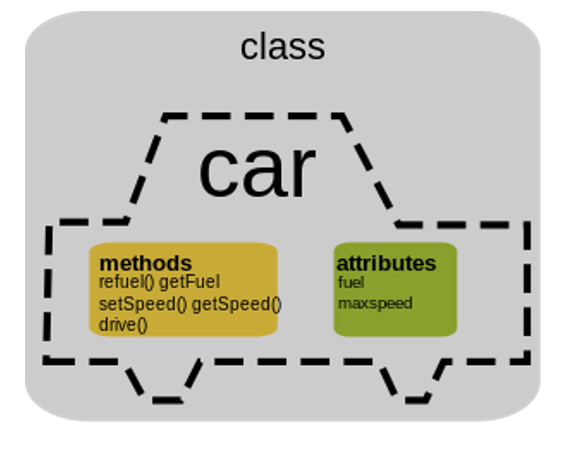

In [ ]:
# funcion vs metodo y una clase sencilla
texto = "hola"
print(len(texto))             # funcion
print(texto.upper())          # metodo
print(type(texto))

class Rectangulo:
    def __init__(self, ancho, alto):
        self.ancho = ancho            # atributos
        self.alto = alto

    def calcular_area(self):
        return self.ancho * self.alto

mi_rectangulo = Rectangulo(4, 3)
otro_rectangulo = Rectangulo(10, 2)


print(mi_rectangulo.calcular_area())
print(Rectangulo.calcular_area(mi_rectangulo))    # forma equivalente
print(otro_rectangulo.calcular_area())

## Unidad 18: Recursion

La **recursion** es una tecnica en la que una funcion se llama a si misma para resolver una version mas pequena del mismo problema.

### 18.1 Concepto de recursion

**Problema que resuelve:** expresar problemas que se definen en terminos de si mismos (cuenta regresiva, factorial, recorrer estructuras).

- **Caso base:** situacion simple que se resuelve directamente y **detiene** la recursion.
- **Caso recursivo:** la funcion se llama a si misma con un problema **mas pequeño**, acercandose al caso base.
- Las llamadas pendientes se apilan en la **pila de ejecucion (call stack)** y se resuelven en orden inverso al volver.
- Sin caso base, la pila crece sin parar y Python lanza `RecursionError` (lo hace al superar el limite, antes de que ocurra el *desbordamiento de pila* real, que es el concepto general de agotar la memoria de llamadas).
- `sys.getrecursionlimit()` (modulo estandar `sys`) muestra el limite.

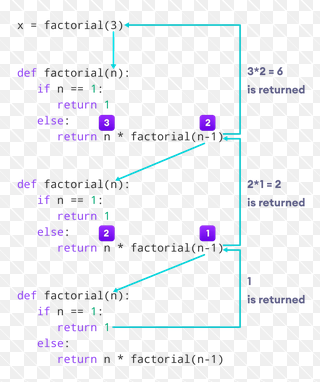

In [ ]:
# Ejemplo de cuenta regresiva, traza de llamadas y RecursionError

def cuenta_regresiva(numero):
    if numero == 0:                  # caso base
        print("Despegue")
    else:                            # caso recursivo
        print(numero)
        cuenta_regresiva(numero - 1)

cuenta_regresiva(3)

3
2
1
Despegue


### 18.2 Factorial: iteracion frente a recursion

**Problema que resuelve:** calcular `n! = n x (n - 1)!`, con caso base `0! = 1` (por ejemplo `4! = 4 x 3 x 2 x 1 = 24`).

- El factorial no esta definido para negativos: `raise ValueError(...)` detiene la funcion y genera un error con mensaje (se ve en 19.4).
- La version iterativa usa un `for`; la recursiva refleja la formula.

| Criterio | Iterativa | Recursiva |
|---|---|---|
| Llamadas | Una | n + 1 |
| Memoria | Constante | Crece con n (pila) |
| Limite | Ninguno practico | Limite de recursion |
| Rendimiento | Algo mas rapido | Algo mas lento (costo de cada llamada) |

`timeit` (biblioteca estandar) mide el tiempo de ejecutar un codigo `number` veces; los valores cambian de un equipo a otro.

In [ ]:
''' ¿Qué es el factorial?
5! = 5 x 4 x 3 x 2 x 1 = 120
Por definición, 0! = 1 '''

# iterativa
def factorial_ciclo(n):
    resultado = 1                        # empezamos en 1
    for numero in range(1, n + 1):       # recorremos 1, 2, 3, ... hasta n
        resultado *= numero
    return resultado


# recursiva
def factorial_recursivo(num):
    if num == 0:                              # caso base: aquí se detiene
        return 1
    return num * factorial_recursivo(num - 1)   # caso recursivo: problema más pequeño


print(factorial_ciclo(5))
print(factorial_recursivo(5))
print(factorial_ciclo(0))
print(factorial_recursivo(0))

### 18.3 Secuencia de Fibonacci

**Problema que resuelve:** generar la secuencia 0, 1, 1, 2, 3, 5, 8... donde cada termino es la suma de los dos anteriores.

- `Fib(0) = 0`, `Fib(1) = 1`, `Fib(n) = Fib(n - 1) + Fib(n - 2)`.
- Hay **dos casos base** y **dos llamadas recursivas** por cada llamada: la version recursiva basica **repite calculos** (por ejemplo `fib(3)` se calcula dos veces dentro de `fib(5)`), asi que el numero de llamadas crece muy rapido.
- `time.perf_counter()` (modulo estandar `time`) es un reloj de alta precision para medir tiempos.

In [ ]:
# A desarrollar

### 18.4 Torre de Hanoi

**Problema que resuelve:** mover `n` discos de la varilla A a la C usando la B como apoyo.

- **Reglas:** un disco por vez, solo el de arriba, nunca uno grande sobre uno pequeno.
- **Idea recursiva:** (1) mover `n - 1` discos de origen a auxiliar, (2) mover el disco grande a destino, (3) mover los `n - 1` de auxiliar a destino. El caso base es `n = 0`.
- Parametros: `cantidad_discos`, `origen`, `destino`, `auxiliar` y `movimientos` (lista donde se anotan los pasos).
- Minimo de movimientos: `M(n) = 2 * M(n - 1) + 1`, es decir `2^n - 1`.

In [ ]:
# A desarrollar

### 18.5 Divide y venceras

**Problema que resuelve:** resolver un problema grande dividiendolo en subproblemas mas pequenos.

1. **Dividir** el problema en partes del mismo tipo.
2. **Resolver** cada parte (normalmente con recursion).
3. **Combinar** los resultados cuando corresponda.

No toda recursion es "divide y venceras": el factorial reduce el problema en 1 y tiene un solo subproblema; la suma por mitades o la busqueda binaria si dividen. El rebanado `lista[:mitad]` toma el inicio y `lista[mitad:]` el final.

```
[4, 2, 7, 1]
   /      \
[4, 2]   [7, 1]      <- se divide en mitades
 /  \     /  \
[4] [2] [7] [1]      <- caso base: un elemento
```

In [ ]:
# A desarrollar

### 18.7 Funciones incorporadas (built-in)

Una **funcion incorporada** es una herramienta que Python ya trae para operaciones comunes. Funciona como una **caja negra**: sabemos que entra, que hace y que sale, sin conocer su implementacion interna.

| Funcion | Recibe | Devuelve |
|---|---|---|
| `abs(n)` | Un numero | Su valor absoluto |
| `min(...)` / `max(...)` | Valores o un iterable | El menor / mayor |
| `len(x)` | Cadena, lista, tupla... | Cantidad de elementos |
| `id(x)` | Un objeto | Entero que identifica al objeto |
| `type(x)` | Un objeto | Su tipo |
| `sorted(it, key, reverse)` | Un iterable | **Lista nueva** ordenada (no modifica la original) |
| `chr(n)` / `ord(c)` | Entero / caracter | Caracter / codigo Unicode |
| `eval(texto)` | Texto con una expresion | El resultado de ejecutarla como codigo |

In [ ]:
# funciones incorporadas
print(abs(-7), abs(3.5))
print(min(4, 9, 2), max(4, 9, 2), max("hola"))
print(len("Python"), len([1, 2, 3]), len((10, 20)))
print(type(5), type(5.0), type("hola"), type([1, 2]), type(True))

7 3.5
2 9 o
6 3 2
<class 'int'> <class 'float'> <class 'str'> <class 'list'> <class 'bool'>


## Unidad 19: Lambda y funciones de orden superior

Una **expresion lambda** es una funcion anonima de una sola expresion. Una **funcion de orden superior** recibe otras funciones como argumentos (o las devuelve): `filter`, `map` y `reduce` son los casos clasicos.

### 19.1 Expresiones lambda

**Problema que resuelve:** crear funciones muy pequenas, de un solo uso, sin escribir un `def` completo.

```
lambda parametros: expresion
```

- **Anonima** significa sin nombre. El resultado de la expresion se **devuelve automaticamente** (sin `return`).
- Solo admite **una expresion**: no puede contener asignaciones, bucles ni `return`.
- Hace el codigo mas simple cuando la funcion es corta y se usa en un solo lugar (`key=`, `map`, `filter`); lo dificulta cuando la logica es larga o necesita explicacion (ahi conviene `def`).

In [ ]:
# equivalencia entre def y lambda

def elevar_al_cuadrado(numero):
    return numero ** 2


elevar_al_cuadrado_lambda = lambda numero: numero ** 2


print(elevar_al_cuadrado(6), elevar_al_cuadrado_lambda(6))


#Ejemplo 2
calcular_area_rectangulo = lambda base, altura: base * altura

clasificar_numero = lambda numero: "par" if numero % 2 == 0 else "impar"



print(calcular_area_rectangulo(4, 3), clasificar_numero(7), clasificar_numero(10))


print((lambda primero, segundo: primero + segundo)(2, 3))   # llamada inmediata, sin nombre


try:
    compile("lambda numero: numero = 2", "<ejemplo>", "exec")
except SyntaxError as error:
    print("SyntaxError esperado (no admite sentencias):", error)

36 36
---------------
---------------
12 impar par
5
SyntaxError esperado (no admite sentencias): cannot assign to lambda (<ejemplo>, line 1)


### 19.2 Funciones de orden superior: filter, map y reduce

**Problema que resuelve:** procesar colecciones completas indicando solo **que** hacer con cada elemento, pasando una funcion como argumento.

En Python las funciones son objetos: se pasan escribiendo **solo su nombre, sin parentesis** (con parentesis se ejecutarian). Un **iterable** es una coleccion que se puede recorrer (lista, tupla, cadena, rango...).

| Funcion | Entrada | Proceso | Resultado |
|---|---|---|---|
| `filter(f, it)` | n elementos | `f` devuelve `True`/`False`; conserva los que cumplen | Iterador con 0 a n elementos |
| `map(f, it)` | n elementos | Aplica `f` a cada elemento | Iterador con n elementos |
| `reduce(f, it)` | n elementos | Acumula con `f(acumulador, elemento)` | **Un solo valor** |

En Python 3, `filter` y `map` devuelven **iteradores**: se convierten con `list(...)` para ver el resultado.

In [ ]:
# pasar funciones como argumentos
def aplicar_operacion(funcion, valor):
    return funcion(valor)

print(aplicar_operacion(abs, -5))
print(aplicar_operacion(len, "hola"))
print(aplicar_operacion(lambda numero: numero * 10, 3))

try:
    aplicar_operacion(abs(-5), -5)       # con parentesis se pasa el resultado (5), no la funcion
except TypeError as error:
    print("TypeError esperado:", error)

#### filter(funcion, iterable)

Evalua la funcion de condicion en cada elemento y **conserva solo los que cumplen**.

In [ ]:
# filter con numeros y cadenas
numeros = [1, 2, 3, 4, 5, 6, 7, 8]

def es_par(numero):
    return numero % 2 == 0

resultado_filter = filter(es_par, numeros)
print(type(resultado_filter))                    # no es una lista
print(list(resultado_filter))

print(list(filter(lambda numero: numero > 5, numeros)))
palabras = ["sol", "luna", "estrella", "mar", "montaña"]
print(list(filter(lambda palabra: len(palabra) > 4, palabras)))
print(list(filter(None, [0, 1, "", "a", None, []])))   # con None se conservan los valores "verdaderos"

#### map(funcion, iterable)

Aplica la funcion a **cada elemento** y los **transforma**: la salida tiene la misma cantidad de elementos.

In [ ]:
# map con lambda, int, str.upper y len
numeros = [1, 2, 3, 4]
print(type(map(abs, numeros)))
print(list(map(lambda numero: numero ** 2, numeros)))
print(list(map(int, ["10", "20", "30"])))
print(list(map(str.upper, ["sol", "luna"])))
print(list(map(len, ["sol", "luna", "estrella"])))
print(list(map(lambda primero, segundo: primero + segundo, [1, 2, 3], [10, 20, 30])))   # con dos iterables

temperaturas_celsius = [0, 10, 100]
print(list(map(lambda celsius: celsius * 9 / 5 + 32, temperaturas_celsius)))

#### reduce(funcion, iterable)

Realiza una **reduccion acumulativa**: combina los elementos de dos en dos hasta quedar con **un solo valor**. La funcion recibe el **acumulador** (resultado parcial) y el siguiente elemento.

- En Python 3 `reduce` no es incorporada: vive en el modulo `functools` (biblioteca estandar), asi que se importa con `from functools import reduce`.
- Sin valor inicial, el acumulador empieza con el primer elemento; con un tercer argumento, empieza con ese **valor inicial**.
- Sin valor inicial, una lista vacia lanza `TypeError`.

In [ ]:
# reduce

from functools import reduce

def sumar(acumulador, numero):
    return acumulador + numero

print(reduce(sumar, [1, 2, 3, 4]))        # 10
print(reduce(sumar, [1, 2, 3, 4], 100))   # 110

### 19.4 Manejo de excepciones

**Problema que resuelve:** que un error previsible (texto que no es numero, division por cero) no detenga todo el programa.

Una **excepcion** es un error que ocurre durante la ejecucion. Un **error de sintaxis** se detecta antes de ejecutar (el codigo esta mal escrito) y no se puede manejar con `try`.

| Bloque | Cuando se ejecuta |
|---|---|
| `try` | Siempre se intenta; contiene el codigo que puede fallar |
| `except` | **Solo si** ocurrio una excepcion |
| `else` | **Solo si NO** ocurrio ninguna excepcion |
| `finally` | **Siempre**, haya o no error |

- Conviene capturar errores **especificos** (`except ValueError:`); `except:` o `except Exception:` sin criterio oculta errores de programacion.
- `as error` da acceso al mensaje; `except (ValueError, TypeError):` captura varios tipos.

In [ ]:
def convertir_a_entero(texto):
    try:
        numero = int(texto)
    except ValueError as error:
        print("No se pudo convertir:", error)
        return None
    else:
        print("Conversion correcta")
        return numero
    finally:
        print("Fin del intento con:", repr(texto))

print(convertir_a_entero("25"))
print(convertir_a_entero("veinte"))

def dividir_numeros(dividendo, divisor):
    try:
        resultado = dividendo / divisor
    except ZeroDivisionError:
        print("No se puede dividir entre cero")
    except TypeError:
        print("Los valores deben ser numeros")
    else:
        print("Resultado:", resultado)
    finally:
        print("Operacion finalizada")

dividir_numeros(10, 2)
dividir_numeros(10, 0)
dividir_numeros(10, "2")

try:
    compile("print('hola'", "<ejemplo>", "exec")      # error de sintaxis: se detecta al compilar
except SyntaxError as error:
    print("SyntaxError detectado:", error.msg)

try:
    resultado_malo = 10 / valor_con_nombre_mal_escrito
except Exception:
    print("Mala practica: algo fallo, pero no sabemos que")

### 19.6 Funciones all() y any()

**Problema que resuelve:** resumir en un solo `True`/`False` una condicion evaluada sobre toda una coleccion.

- **Valores falsos:** `False`, `None`, `0`, `0.0`, `""`, `[]`, `()`, `{}`. Casi todo lo demas es verdadero (incluso `"0"` y `[0]`).
- `all(it)` es `True` si **todos** los elementos son verdaderos; con una coleccion vacia da `True`.
- `any(it)` es `True` si **al menos uno** es verdadero; con una coleccion vacia da `False`.
- Se detienen en cuanto conocen la respuesta. Para validar condiciones se combinan con `map`.

In [ ]:
print(bool(0), bool(""), bool([]), bool(None), bool("0"), bool([0]))


positivos = [3, 8, 12]
mezclados = [3, -8, 12]

# all(): True solo si TODOS los elementos son verdaderos
print(all(map(lambda numero: numero > 0, positivos)))    # True (todos son > 0)
print(all(map(lambda numero: numero > 0, mezclados)))    # False (-8 no es > 0)

# any(): True si AL MENOS UNO es verdadero
print(any(map(lambda numero: numero > 10, mezclados)))   # True (12 es > 10)
print(any(map(lambda numero: numero > 100, mezclados)))  # False (ninguno es > 100)

# Caso especial con listas vacías

print("Listas vacias:", all([]), any([]))
# Salida: Listas vacias: True False


def clave_valida(clave):
    tiene_longitud = len(clave) >= 8                                          # 8 o más caracteres
    tiene_digito = any(map(lambda caracter: caracter.isdigit(), clave))       # al menos un dígito
    tiene_mayuscula = any(map(lambda caracter: caracter.isupper(), clave))    # al menos una mayúscula
    return tiene_longitud and tiene_digito and tiene_mayuscula                # deben cumplirse las tres

print(clave_valida("Clave2024"), clave_valida("clave2024"), clave_valida("Clave"))

### 19.7 Comprensiones de listas frente a lambda, map y filter

**Problema que resuelve:** construir una lista nueva a partir de otra (transformando y/o filtrando) en una sola expresion legible.

```
[expresion for elemento in iterable if condicion]
```

| Tarea | Comprension | map / filter |
|---|---|---|
| Transformar | `[n ** 2 for n in numeros]` | `list(map(lambda n: n ** 2, numeros))` |
| Filtrar | `[n for n in numeros if n % 2 == 0]` | `list(filter(lambda n: n % 2 == 0, numeros))` |

| | Comprension | map / filter con lambda |
|---|---|---|
| Legibilidad | Normalmente la mas clara | Mas densa al combinarlas |
| Resultado | Lista inmediata | Iterador (evaluacion diferida) |
| Cuando usarla | Transformaciones y filtros sencillos | Cuando ya existe una funcion con nombre (`map(int, textos)`) o se quiere un iterador |

Prioriza el codigo legible y el estilo idiomatico de Python.

In [ ]:
# Ejemplo 1 (General): equivalencias
numeros = [1, 2, 3, 4, 5, 6]

cuadrados_comprension = [numero ** 2 for numero in numeros]
cuadrados_map = list(map(lambda numero: numero ** 2, numeros))
print(cuadrados_comprension, cuadrados_comprension == cuadrados_map)


pares_comprension = [numero for numero in numeros if numero % 2 == 0]
pares_filter = list(filter(lambda numero: numero % 2 == 0, numeros))
print(pares_comprension, pares_comprension == pares_filter)


ambas_comprension = [numero ** 2 for numero in numeros if numero % 2 == 0]
ambas_map_filter = list(map(lambda numero: numero ** 2, filter(lambda numero: numero % 2 == 0, numeros)))
print(ambas_comprension, ambas_comprension == ambas_map_filter)



# Equivalente con bucle tradicional
pares_bucle = []
for numero in numeros:
    if numero % 2 == 0:
        pares_bucle.append(numero)
print("Mismo resultado con bucle:", pares_bucle == pares_comprension)